In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [13]:
# Read image as grayscale
img = cv2.imread("sink.jpg", 0)

# Convert image to binary
_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

# 3x3 structuring element
kernel = np.ones((3, 3))

In [3]:
# --------------------------------
# Manual Erosion
# --------------------------------
def erosion(image, kernel):

    h, w = image.shape
    result = np.zeros((h, w), dtype=np.uint8)

    for i in range(1, h - 1):
        for j in range(1, w - 1):

            region = image[i-1:i+2, j-1:j+2]

            # If all pixels under kernel are white
            if np.all(region[kernel == 1] == 255):
                result[i, j] = 255
            else:
                result[i, j] = 0

            # if np.all(region == 255):
            #     result[i, j] = 255
            # else:
            #     result[i, j] = 0

    return result



In [4]:
# --------------------------------
# Manual Dilation
# --------------------------------
def dilation(image, kernel):

    h, w = image.shape
    result = np.zeros((h, w), dtype=np.uint8)

    for i in range(1, h - 1):
        for j in range(1, w - 1):

            region = image[i-1:i+2, j-1:j+2]

            # If at least one pixel is white
            if np.any(region[kernel == 1] == 255):
                result[i, j] = 255
            else:
                result[i, j] = 0

    return result



In [5]:
# --------------------------------
# Perform Erosion
# --------------------------------
eroded = erosion(binary, kernel)


# --------------------------------
# Perform Dilation
# --------------------------------
dilated = dilation(binary, kernel)


# --------------------------------
# Opening
# Erosion -> Dilation
# --------------------------------
opened = dilation(eroded, kernel)


# --------------------------------
# Closing
# Dilation -> Erosion
# --------------------------------
closed = erosion(dilated, kernel)

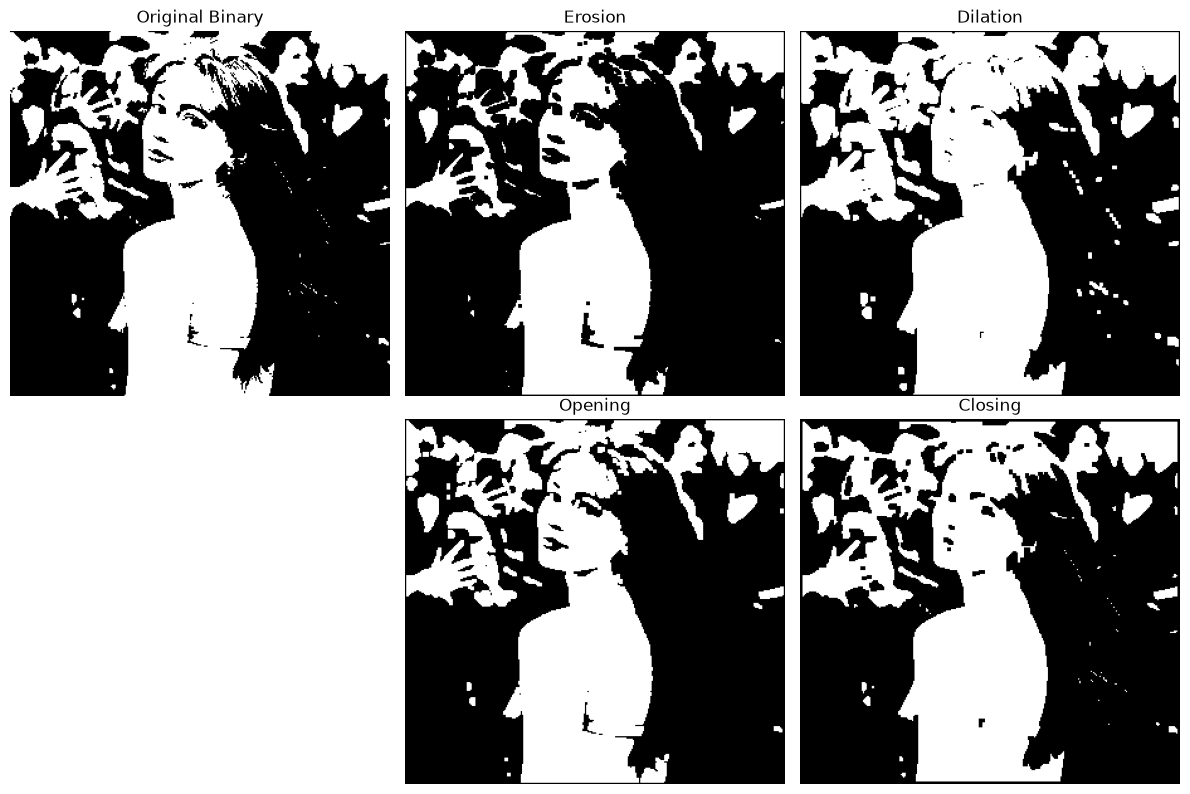

In [6]:
# --------------------------------
# Display results
# --------------------------------

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Binary")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(eroded, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(dilated, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(opened, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(closed, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()